# 13-ETF benchmark study

This standalone historical experiment checks the allocation engine on a smaller universe. Its eleven blends and scores belong to the ETF experiment. The [main research notebook](../../RiskMatch_V2.ipynb) presents the multi-asset study in section 6.

### ETF benchmark · Construct distinct allocations

return maximizes net estimate. Robust maximizes the least good net return of three models and must respect the ceiling in each. Diversification minimizes the sum of the squares of the weights of the funds and of the liquid investment sleeve before fresh. Coverage maximizes the final value under the chosen shock. The latter two can return up to 2.5 points of estimated return against return. Two options are grouped if the half-sum of the weight differences, including cash, is not more than 0.5 points. The fixed reference invests 60% in SPY and 40% in IEF. The November detailed positions allow separate control of the issuers, following the October decision.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Support execution from either the project root or this report directory.
import os
import sys
project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/options-6.json").is_file())
os.chdir(project)
sys.path.insert(0, str(project / "src"))

opt_dir=Path("reports/06-options")
six=json.loads((opt_dir/"resultats.json").read_text())
policy6=json.loads(Path("config/options-6.json").read_text())
fiches=pd.DataFrame(six["cards"]).T
display(fiches[["net","vol","hhi","valid"]].rename(columns={"net":"Estimated return (decimal)","vol":"Volatility (decimal)","hhi":"Concentration by funds","valid":"In the mandate"}))
display(pd.DataFrame({n:c["weights"] for n,c in six["cards"].items()}).mul(100).round(2))
print("Variations grouped:",six["aliases"],"· environment:",six["environmental"])
from importlib.util import find_spec

catalogue6 = Path("data/local/4") / policy6["catalogue"]
if (catalogue6 / "prices.parquet").is_file() and all(find_spec(x) for x in ("duckdb", "cvxpy", "sklearn", "pyarrow")):
    from riskmatch_v2.options.compare import models, weights
    from riskmatch_v2.options.study import context

    cfg6, params6, _, daily6, shock6, _ = context()
    models6 = models(daily6.loc[:cfg6["market"]], params6)
    candidates6 = weights(models6, shock6, cfg6["risk_cap"], cfg6["return_concession"])
    for name, computed in candidates6.items():
        stored = [six["cards"][name]["weights"][ticker] for ticker in models6[0].names]
        np.testing.assert_allclose(computed, stored, atol=1e-6)
    print("The allocations recalculated on the local archives are consistent with the records.")
else:
    print("Public reading of allocations from aggregate sheets.")


,Estimated return (decimal),Volatility (decimal),Concentration by funds,In the mandate
Return,0.113966,0.12,0.177185,True
Robust,0.112538,0.118289,0.174579,True
Diversification,0.088966,0.119828,0.075042,True
Hedge,0.088966,0.12,0.358751,True
60/40 benchmark,0.080311,0.127618,0.52,False


,Return,Robust,Diversification,Hedge,60/40 benchmark
GLD,25.87,25.90,8.15,49.21,0.0
IEF,4.34,5.76,5.15,31.91,40.0
SPY,0.00,0.00,7.50,0.00,60.0
TLT,0.00,0.00,4.60,0.00,0.0
XLB,0.00,0.00,6.17,0.00,0.0
XLE,20.60,20.14,9.51,6.49,0.0
XLF,0.00,0.00,6.64,0.00,0.0
XLI,0.00,0.00,7.05,0.00,0.0
XLK,15.46,14.79,9.68,2.39,0.0
XLP,7.46,7.04,6.01,0.00,0.0


Variations grouped: {} · environment: Metrics and coverage to be validated in section 11


The allocations recalculated on the local archives are consistent with the records.


### ETF benchmark · Separate historical results, estimates and shocks

The range ranges from the lowest to the highest returns of the three models. It expresses sensitivity to assumptions. The estimated Sharpe uses CHF cash at 0% per year and the estimated annual return after fees. Contributions from Euler amount to annual volatility. The historical column is the net compound return of the annual decision replay. A negative loss under shock indicates a hypothetical gain. The coverage per issuer is partial, in particular for gold.

In [2]:
for c in six["cards"].values():
    assert abs(sum(c["euler"].values())-c["vol"])<1e-7
comparaison=pd.DataFrame({n:{"Net history (%/year)":100*c["cagr"],"Low estimate (%)":100*c["interval"][0],
    "High estimate (%)":100*c["interval"][1],"Annual variance":c["variance"],"Estimated Sharp":c["sharpe"],
    "Loss of impact (%)":100*c["loss"],"6% deviation (CHF/year)":c["goal_gap_chf"],
    "Gross unknown issuer exposure (%)":100*six["issuer"][n]["unknown_weight"]} for n,c in six["cards"].items()}).T
display(comparaison.round(3))

,Net history (%/year),Low estimate (%),High estimate (%),Annual variance,Estimated Sharp,Loss of impact (%),6% deviation (CHF/year),Gross unknown issuer exposure (%)
Return,6.833,9.405,13.979,0.014,0.950,16.129,1888.799,26.121
Robust,7.513,9.334,13.848,0.014,0.951,15.480,1838.824,26.155
Diversification,5.730,8.155,12.736,0.014,0.742,23.027,1013.799,8.451
Hedge,2.403,8.155,12.311,0.014,0.741,-3.280,1013.799,49.613
60/40 benchmark,6.723,8.031,12.538,0.016,0.629,15.798,710.874,0.564


### ETF benchmark · Replay nine annual decisions

The last session of October sets the target with the observations available until its closing in the historic game. The first transactions are possible at the close of the next session if price and exchange are observed. The registry tracks units, splits and distributions. The latter are credited on the ex-supplementary date, due to lack of individual payment dates. The same withdrawal of CHF 1,000 was requested in the investment sleeve on 31 March 2022. Sales release cash after a session. The external reserve remains intact.

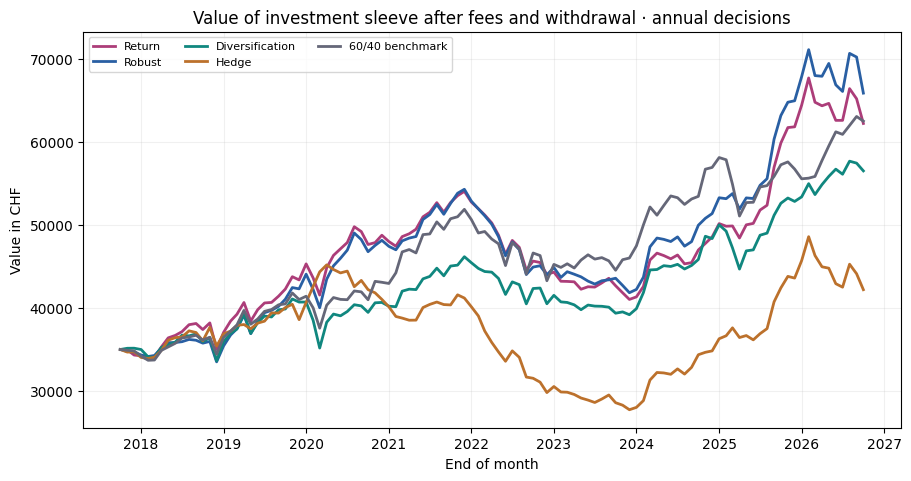

Decisions: ['2017-10-31', '2018-10-31', '2019-10-31', '2020-10-30', '2021-10-29', '2022-10-31', '2023-10-31', '2024-10-31', '2025-10-31']


In [3]:
hist=pd.DataFrame(six["monthly_chf"])
hist.index=pd.to_datetime(hist.index)
fig,ax=plt.subplots(figsize=(9,4.7),layout="constrained")
for (name,series),color in zip(hist.items(),["#ac3d79","#295fa3","#10877f","#bc712c","#656778"]):
    ax.plot(series.index,series,label=name,color=color,linewidth=2 if "Conference" not in name else 1.2)
ax.set(title="Value of investment sleeve after fees and withdrawal · annual decisions",ylabel="Value in CHF",xlabel="End of month")
ax.legend(ncol=3,fontsize=8);ax.grid(alpha=.18)
fig.savefig(opt_dir/"rejeu.png",dpi=160);plt.show()
print("Decisions:",six["signals"])

### ETF benchmark · Reconcile cash flows

The accounting identity verifies each day the previous value, the price change of the positions held, distributions, the external flows actually served and charges. A second reconciliation finds wealth from positions, bank cash and amounts to be settled. The example executed below shows why selling a title and immediately disposing of its product would lead to different orders.

In [4]:
from riskmatch_v2.options.replay import Tape,replay
days=["2025-06-02","2025-06-03","2025-06-04","2025-06-05","2025-06-06","2025-06-09"]
usd=np.array([[9,20],[10,20],[11,20],[11,20],[11,20],[11,20]],float)
toy=Tape(days,["A","B"],usd,np.ones(6),usd,np.ones_like(usd,bool),np.zeros_like(usd),np.ones_like(usd))
toy_result,book_daily,trades,units,_=replay(toy,{days[0]:[.8,0],days[2]:[0,1]},1000,150,fee=0,flows={days[2]:-100},capture=True)
display(book_daily[["nav","positions","cash","pending","purchase_payable","flow","residual"]].join(units))
assert units.iloc[3].tolist()==[0,5] and units.iloc[4].tolist()==[0,49]
assert toy_result["final"]==980 and toy_result["paid"]==100
assert max(r["max_residual"] for runs in six["runs"].values() for r in runs.values())<1e-6

,nav,positions,cash,pending,purchase_payable,flow,residual,A,B
day,,,,,,,,,
2025-06-02,1000.0,0.0,1000.0,0.0,0.0,0.0,0.0,0.0,0.0
2025-06-03,1000.0,800.0,200.0,0.0,800.0,0.0,0.0,80.0,0.0
2025-06-04,980.0,880.0,100.0,0.0,0.0,-100.0,0.0,80.0,0.0
2025-06-05,980.0,100.0,0.0,880.0,100.0,0.0,0.0,0.0,5.0
2025-06-06,980.0,980.0,0.0,0.0,880.0,0.0,0.0,0.0,49.0
2025-06-09,980.0,980.0,0.0,0.0,0.0,0.0,0.0,0.0,49.0


### ETF benchmark · Measure execution effects

Scenarios replay exactly the target dates of the central case. Negotiated quantities are recalculated after drift and costs. The 100% asset reference may lack cash for the withdrawal requested. The final wealth and the amount actually withdrawn must therefore be read together. Risk exceedance is based on 63-series moving windows of realized returns.

In [5]:
richesse=pd.DataFrame({n:{s:r["final"] for s,r in runs.items()} for n,runs in six["runs"].items()})
display(richesse.round(2))
exécution=pd.DataFrame({n:r["central"] for n,r in six["runs"].items()}).T
display(exécution[["fees","turnover","paid","unpaid","vol_breaches","crisis_2020","annee_2022"]].round(3))

,Return,Robust,Diversification,Hedge,60/40 benchmark
central,62218.52,65870.89,56507.87,42201.99,62499.25
no fees,62642.78,66232.01,56715.73,42523.11,62591.43
25 bp,61586.34,65332.19,56197.19,41723.35,62361.15
wider spread,60543.84,64442.27,55682.17,40933.68,62131.79
one extra session,60761.02,64879.25,56613.14,40806.31,62653.62
first basket missed,57752.39,64014.28,54564.18,40666.42,60207.94
whole units,62072.85,65702.11,55928.78,42130.96,62229.11


,fees,turnover,paid,unpaid,vol_breaches,crisis_2020,annee_2022
Return,319.847,7.143,1000.000,0.000,1060.0,-0.195,-0.170
Robust,254.387,5.762,1000.000,0.000,1023.0,-0.205,-0.174
Diversification,161.412,3.862,1000.000,0.000,776.0,-0.239,-0.103
Hedge,269.433,7.724,1000.000,0.000,836.0,0.092,-0.257
60/40 benchmark,59.862,1.504,272.856,727.144,754.0,-0.185,-0.161


### ETF benchmark · Recalculate the client score

The score combines objective, net history and maximum decline, designated shock, concentration and fresh. The full grid reserves 10 points to the validated forecasts. Without the four families validated for the CHF target at 12 months, both profiles use the same five available criteria and their weights are restandardized to 90. Non-term options remain visible as references and are excluded from the score. The sheets are search simulations. Account control does not produce any real investment score.

,subscores,contributions
goal,93.781526,36.470594
history,63.544469,10.590745
stress,48.400277,8.066713
spread,91.713441,15.285574
cost,64.000000,7.111111


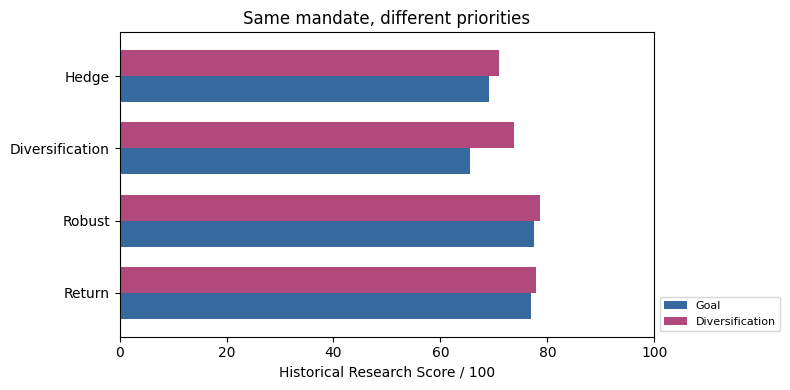

Coverage: 90 % · excluded: {'60/40 benchmark': 'outside mandate or unverified negotiability'} · Actual scores: {}


In [6]:
from riskmatch_v2.options.scoring import rank
ranked={client:rank(six["cards"],weights,policy6,research=True) for client,weights in policy6["profiles"].items()}
scores=pd.DataFrame({client:{n:r["total"] for n,r in grid["rows"].items()} for client,grid in ranked.items()})
for name,row in ranked["Goal"]["rows"].items():
    assert abs(sum(row["contributions"].values())-row["total"])<1e-9
display(pd.DataFrame(ranked["Goal"]["rows"]["Robust"])[["subscores","contributions"]])
ax=scores.plot.barh(color=["#366a9e","#b2497c"],figsize=(8,4),width=.72)
ax.set(xlim=(0,100),xlabel="Historical Research Score / 100",ylabel="",title="Same mandate, different priorities")
ax.legend(loc="lower left",bbox_to_anchor=(1,0),fontsize=8)
ax.figure.tight_layout();ax.figure.savefig(opt_dir/"scores.png",dpi=160);plt.show()
print("Coverage:",ranked["Goal"]["coverage"],"% · excluded:",ranked["Goal"]["excluded"],"· Actual scores:",six["account_scores"])

### ETF benchmark · Check coverage and near ties

The ranking consists of options at two points or less from the best of their group. The missing essential data prevents the overall score. The fictitious control activates four validated signals, then removes the validation of the feeling and slightly disrupts the performance of an option. In the actual results of the project, the forecast validation remains to be carried out in Section 12.

In [7]:
from riskmatch_v2.options.scenarios import scoring_controls
proofs=scoring_controls(policy6)
display(pd.DataFrame({k:{"Coverage (%)":g["coverage"],"Score A":g["rows"]["A"]["total"],"Score B":g["rows"]["B"]["total"],
                         "Group A":g["rows"]["A"]["group"],"Group B":g["rows"]["B"]["group"]} for k,g in proofs.items()}).T.round(3))
display(pd.DataFrame({k:{name:v["groupe"] for name,v in rows.items()} for k,rows in six["sensitivity"]["Diversification"].items()}))
print(six["signal_status"])

,Coverage (%),Score A,Score B,Group A,Group B
full,100.0,64.396,64.425,1.0,1.0
missing_sentiment,90.0,64.329,64.361,1.0,1.0
reversal,90.0,64.394,64.361,1.0,1.0


,low bound,high bound,diversification priority +5
Return,1,1,1
Robust,1,1,1
Diversification,2,1,2
Hedge,3,2,3


{'macro': 'not validated for the 12-month target', 'market': 'not validated for the 12-month target', 'quantitatif': 'not validated for the 12-month target', 'sentiment': 'not validated for the 12-month target'}


### ETF benchmark · Combine holdings and recalculate orders

The share of a common title is the sum of its weights in the components multiplied by their shares. Orders are calculated on the aggregate portfolio, then net costs and volatility are recalculated. The reserve of CHF 15,000 remains external. The graph shows the funds held by the 60% test mixture Performance and 40% Diversification. Cash and expenses are the original budget.

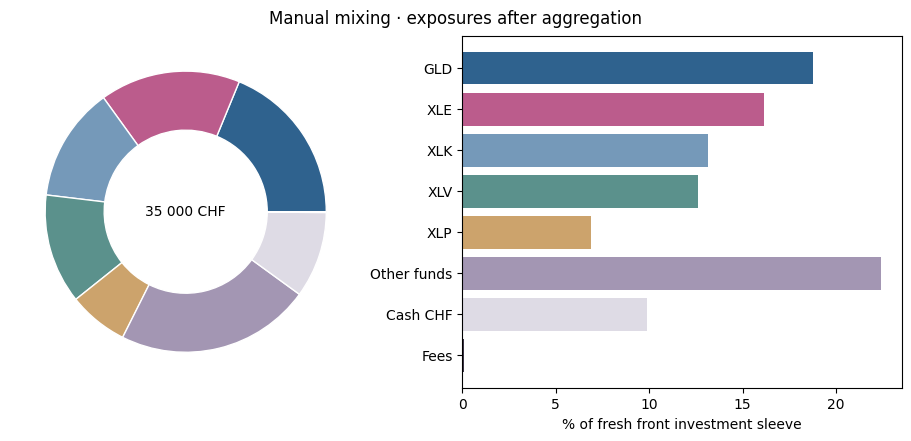

Simulated batches: [22.0, 22.0, 2.0, 10.0, 20.0, 98.0, 20.0, 7.0, 31.0, 32.0, 23.0, 29.0, 9.0] · cash CHF 3514.09 · CHF fee 31.45


,Continu,Simulated whole parts
Goal,73.155648,72.979462
Diversification,77.912712,77.856589


In [8]:
assert abs(.60*.20+.40*.10-.16)<1e-12
mix=six["mixes"]["Manual 60/40"]
c=mix["card"]
weights6=pd.Series(c["weights"])
for sym,w in weights6.items():
    assert abs(w-sum(share*six["cards"][name]["weights"][sym] for name,share in mix["parts"].items()))<1e-8
composition=weights6.sort_values(ascending=False)
top=composition.head(5).copy()
top["Other funds"]=composition.iloc[5:].sum()
top["Cash CHF"]=c["cash"]
top["Fees"]=c["fee"]
assert abs(top.sum()-1)<1e-6
fig,(left,right)=plt.subplots(1,2,figsize=(9,4.3),layout="constrained",gridspec_kw={"width_ratios":[1,1.25]})
colors=["#2f628e","#bb5c8c","#7599b9","#5b918c","#cca36c","#a396b3","#dedbe5","#3e3749"]
left.pie(top,colors=colors,wedgeprops={"width":.42,"edgecolor":"white"})
left.text(0,0,"35 000 CHF",ha="center",va="center")
right.barh(top.index,top*100,color=colors);right.invert_yaxis();right.set_xlabel("% of fresh front investment sleeve")
fig.suptitle("Manual mixing · exposures after aggregation")
fig.savefig(opt_dir/"melange.png",dpi=160);plt.show()
ordre=mix["rounding"]["order"]
print("Simulated batches:",ordre["units"],"· cash CHF",round(ordre["cash_chf"],2),"· CHF fee",round(ordre["fee_chf"],2))
display(pd.DataFrame({"Continu":mix["scores"],"Simulated whole parts":mix["rounding"]["scores"]}))

### ETF benchmark · Compare blends

The proposed shares continue with the estimated net return, minimum risk or Sharpe estimated on the investment sleeve in CHF at one year. The calculation uses the covariance of the underlying securities of the target allocation. The history of each mixture is derived from an annual review of the aggregate targets. Sharpe's estimates of a zero variance or premium with an uncertain sign are excluded. Multi-departure solvers produce verified candidates. Minimum shares are only imposed when the customer so wishes.

In [9]:
display(pd.DataFrame({n:{**{k:round(100*v,2) for k,v in x["parts"].items()},
                         "Estimated return (%)":100*x["card"]["net"],"Volatility (%)":100*x["card"]["vol"],
                         "Sharpe":x["card"]["sharpe"],"Net history (%/year)":100*x["card"]["cagr"]}
                     for n,x in six["mixes"].items()}).T.round(3))
print("Search Status Sharpe:",six["searches"]["Sharpe · free"]["status"])
print("Account Decision:",six["admission"])

,Return,Diversification,Hedge,Estimated return (%),Volatility (%),Sharpe,Net history (%/year)
Manual 60/40,60.00,40.00,0.00,10.397,11.680,0.890,6.445
Equal weight,33.33,33.33,33.33,9.730,10.783,0.902,5.091
Only · Performance,100.00,0.00,0.00,11.397,12.000,0.950,6.833
Alone · Diversification,0.00,100.00,0.00,8.897,11.983,0.742,5.730
Alone · Coverage,0.00,0.00,100.00,8.897,12.000,0.741,2.403
Performance · free,100.00,0.00,0.00,11.397,12.000,0.950,6.833
Performance · minimum 10%,80.00,10.00,10.00,10.897,11.586,0.940,6.319
Sharpe · free,92.79,0.00,7.21,11.216,11.796,0.951,6.528
Sharpe · minimum 10 %,79.58,10.00,10.42,10.886,11.575,0.940,6.302
Minimum risk · free,0.00,50.14,49.86,8.897,10.371,0.858,4.176


Search Status Sharpe: candidate verified
Account Decision: {'screened': 27507, 'eligible': 0, 'date': '2026-11-23T14:00:00Z'}
